In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


In [3]:
print("Shape:", df_pe.shape)
print(df_pe.Is_Malware.value_counts(), "\nPrevalence:", round(df_pe.Is_Malware.mean(),3))
print("Missing:\n", df_pe.isna().sum()[lambda s: s>0])
print("Duplicate rows:", df_pe.duplicated().sum(),
      "| duplicates ignoring ID:", df_pe.drop(columns="SHA256_File_ID").duplicated().sum())
display(df_pe.describe().T)

Shape: (6000, 15)
Is_Malware
0    4389
1    1611
Name: count, dtype: int64 
Prevalence: 0.268
Missing:
 Import_Count        229
Resource_Entropy    289
dtype: int64
Duplicate rows: 0 | duplicates ignoring ID: 0


,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709010,1.170152,2.146111,4.821742,5.639862,6.604762,7.990000
Import_Count,5771.0,83.386866,50.301130,0.000000,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,2.800167,3.094430,0.000000,1.000000,2.000000,3.000000,24.000000
Has_Valid_Signature,6000.0,0.630833,0.482619,0.000000,0.000000,1.000000,1.000000,1.000000
Has_RWX_Section,6000.0,0.149833,0.356938,0.000000,0.000000,0.000000,0.000000,1.000000
Virtual_to_Raw_Size_Ratio,6000.0,984.890348,9868.008483,0.367195,0.955570,1.129836,1.366755,99999.000000
Resource_Entropy,5711.0,4.535160,1.501097,0.000000,3.483114,4.432941,5.517712,7.990000
Num_Embedded_URLs_IPs,6000.0,1.468333,1.951742,0.000000,0.000000,1.000000,2.000000,11.000000
Abnormal_Compile_Timestamp,6000.0,0.114833,0.318847,0.000000,0.000000,0.000000,0.000000,1.000000
Num_Sections,6000.0,4.758667,1.784551,1.000000,3.000000,5.000000,6.000000,10.000000


Sentinel 99999.0 count: 59


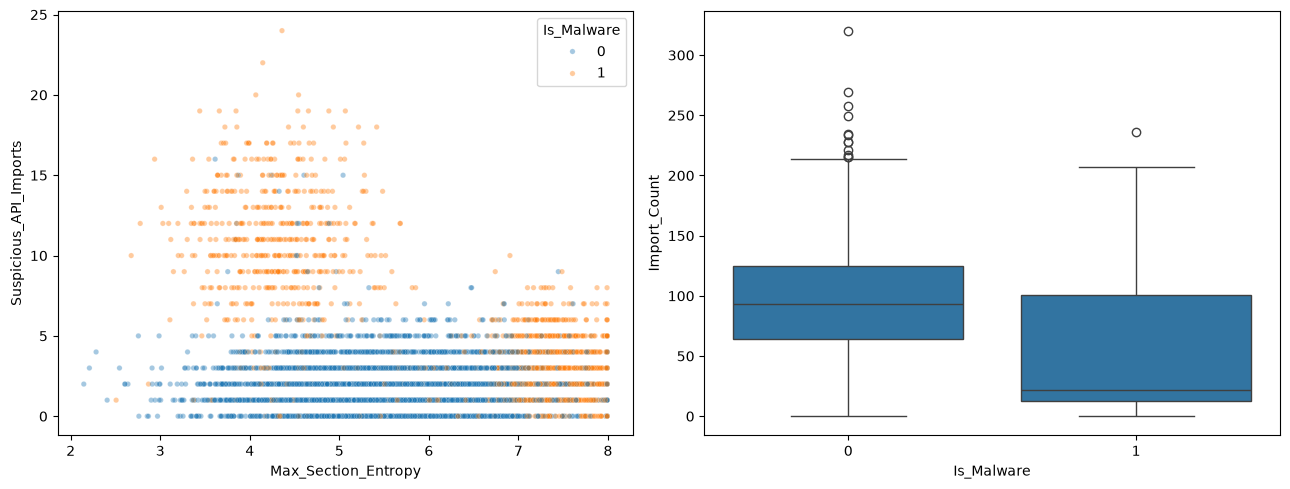

In [4]:
import seaborn as sns
print("Sentinel 99999.0 count:", (df_pe.Virtual_to_Raw_Size_Ratio==99999.0).sum())
fig, ax = plt.subplots(1, 2, figsize=(13,5))
sns.scatterplot(data=df_pe, x="Max_Section_Entropy", y="Suspicious_API_Imports",
                hue="Is_Malware", alpha=.4, s=15, ax=ax[0])
sns.boxplot(data=df_pe, x="Is_Malware", y="Import_Count", ax=ax[1])
plt.tight_layout(); plt.show()

In [5]:
X = df_pe.drop(columns=["SHA256_File_ID","VT_PostScan_Detections","Is_Malware"]).copy()
X.loc[X.Virtual_to_Raw_Size_Ratio==99999.0, "Virtual_to_Raw_Size_Ratio"] = np.nan
y = df_pe.Is_Malware
print(X.shape); print(X.columns.tolist())
print("Ratio NaN now:", X.Virtual_to_Raw_Size_Ratio.isna().sum())

(6000, 12)
['Max_Section_Entropy', 'Import_Count', 'Suspicious_API_Imports', 'Has_Valid_Signature', 'Has_RWX_Section', 'Virtual_to_Raw_Size_Ratio', 'Resource_Entropy', 'Num_Embedded_URLs_IPs', 'Abnormal_Compile_Timestamp', 'Num_Sections', 'Has_TLS_Callback', 'Export_Count']
Ratio NaN now: 59


In [6]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
try:
    from lightgbm import LGBMClassifier
    boost = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1); bname = "LightGBM"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    boost = HistGradientBoostingClassifier(random_state=SEED); bname = "HistGradientBoosting (fallback, not LightGBM)"
imp = lambda: SimpleImputer(strategy="median")
models = {
 "LogReg": Pipeline([("imp",imp()),("sc",RobustScaler()),("clf",LogisticRegression(max_iter=2000,random_state=SEED))]),
 "DeepTree": Pipeline([("imp",imp()),("clf",DecisionTreeClassifier(random_state=SEED))]),
 "RandomForest": Pipeline([("imp",imp()),("clf",RandomForestClassifier(n_estimators=300,n_jobs=-1,random_state=SEED))]),
 bname: Pipeline([("imp",imp()),("clf",boost)]),
}
models["Stacking"] = StackingClassifier(
    estimators=[("lr",models["LogReg"]),("rf",models["RandomForest"]),("gb",models[bname])],
    final_estimator=LogisticRegression(max_iter=2000), cv=5, n_jobs=-1)
print("Boosting model:", bname)
print(X_dev.shape, X_test.shape, "dev prev:", round(y_dev.mean(),3), "test prev:", round(y_test.mean(),3))

Boosting model: HistGradientBoosting (fallback, not LightGBM)
(4800, 12) (1200, 12) dev prev: 0.269 test prev: 0.268


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for n, m in models.items():
    r = cross_validate(m, X_dev, y_dev, cv=cv, scoring={"f1":"f1","pr_auc":"average_precision"}, return_train_score=True)
    rows.append({"Model":n, "Train_F1":r["train_f1"].mean(), "Val_F1":r["test_f1"].mean(),
                 "Val_F1_std":r["test_f1"].std(), "Val_PR_AUC":r["test_pr_auc"].mean(), "Fit_s":r["fit_time"].mean()})
res = pd.DataFrame(rows); res["Gap"] = res.Train_F1 - res.Val_F1
display(res.round(4).sort_values("Val_PR_AUC", ascending=False))

,Model,Train_F1,Val_F1,Val_F1_std,Val_PR_AUC,Fit_s,Gap
4,Stacking,0.9325,0.9244,0.0088,0.9091,19.4021,0.0080
0,LogReg,0.9231,0.9238,0.0084,0.9080,0.0754,-0.0007
3,"HistGradientBoosting (fallback, not LightGBM)",0.9770,0.9213,0.0088,0.9061,2.1900,0.0557
2,RandomForest,1.0000,0.9237,0.0091,0.9054,1.7312,0.0763
1,DeepTree,1.0000,0.8301,0.0135,0.7330,0.0773,0.1699


In [8]:
fitted = {n: clone(models[n]).fit(X_dev, y_dev) for n in ["LogReg","RandomForest",bname]}
for n, m in fitted.items():
    m.predict_proba(X_test[:100])  # warm-up
    ts = []
    for _ in range(20):
        t = time.perf_counter(); m.predict_proba(X_test); ts.append(time.perf_counter()-t)
    print(f"{n}: {np.median(ts)/len(X_test)*1e6:.2f} ms per 1,000 files (batch of {len(X_test)})")

LogReg: 3.60 ms per 1,000 files (batch of 1200)
RandomForest: 173.03 ms per 1,000 files (batch of 1200)
HistGradientBoosting (fallback, not LightGBM): 19.35 ms per 1,000 files (batch of 1200)


In [9]:
fitted = {n: clone(models[n]).fit(X_dev, y_dev) for n in ["LogReg","RandomForest",bname]}
for n, m in fitted.items():
    m.predict_proba(X_test[:100])  # warm-up
    ts = []
    for _ in range(20):
        t = time.perf_counter(); m.predict_proba(X_test); ts.append(time.perf_counter()-t)
    print(f"{n}: {np.median(ts)/len(X_test)*1e6:.2f} ms per 1,000 files (batch of {len(X_test)})")

LogReg: 3.83 ms per 1,000 files (batch of 1200)
RandomForest: 167.25 ms per 1,000 files (batch of 1200)
HistGradientBoosting (fallback, not LightGBM): 20.35 ms per 1,000 files (batch of 1200)


In [10]:
p_lr = fitted["LogReg"].predict_proba(X_test)[:,1]
p_tr = fitted[bname].predict_proba(X_test)[:,1]
cmp = X_test.copy(); cmp["y_true"]=y_test.values; cmp["p_LR"]=p_lr; cmp["p_tree"]=p_tr
cmp["pred_LR"]=(p_lr>=0.5).astype(int); cmp["pred_tree"]=(p_tr>=0.5).astype(int)
print("Total disagreements (threshold 0.5):", (cmp.pred_LR!=cmp.pred_tree).sum())
cand = cmp[(cmp.y_true==1)&(cmp.pred_LR==0)&(cmp.pred_tree==1)]
print("Malware missed by LR but caught by tree:", len(cand))
if len(cand)==0:
    print("No such case -> using another disagreement instead")
    cand = cmp[cmp.pred_LR!=cmp.pred_tree]
idx = cand.assign(d=(cand.p_tree-cand.p_LR).abs()).sort_values("d", ascending=False).index[0]
print("Row index:", idx, "| ID:", df_pe.loc[idx,"SHA256_File_ID"])
display(cmp.loc[[idx]].T)

Total disagreements (threshold 0.5): 5
Malware missed by LR but caught by tree: 1
Row index: 5115 | ID: sha256_05115_pe


,5115
Max_Section_Entropy,7.221465
Import_Count,13.184508
Suspicious_API_Imports,1.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,2.330997
Resource_Entropy,5.381376
Num_Embedded_URLs_IPs,1.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,10.000000


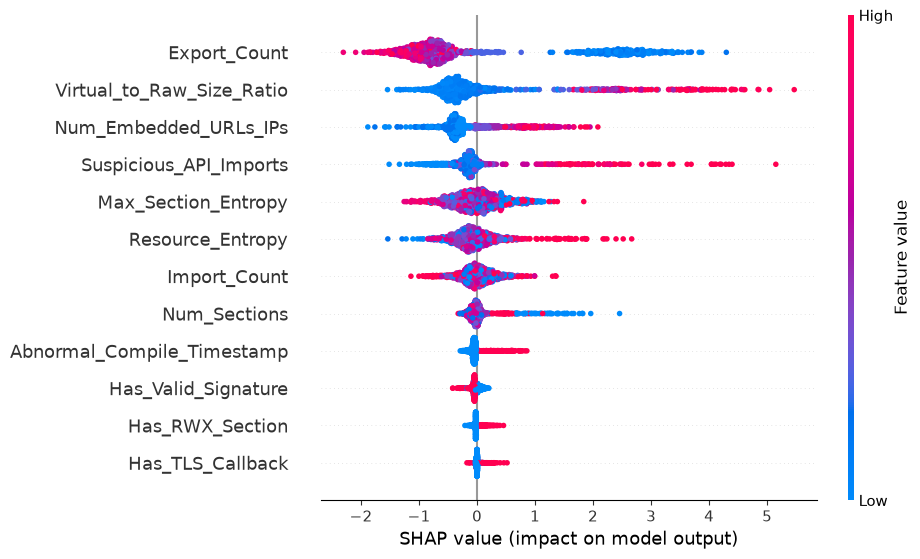

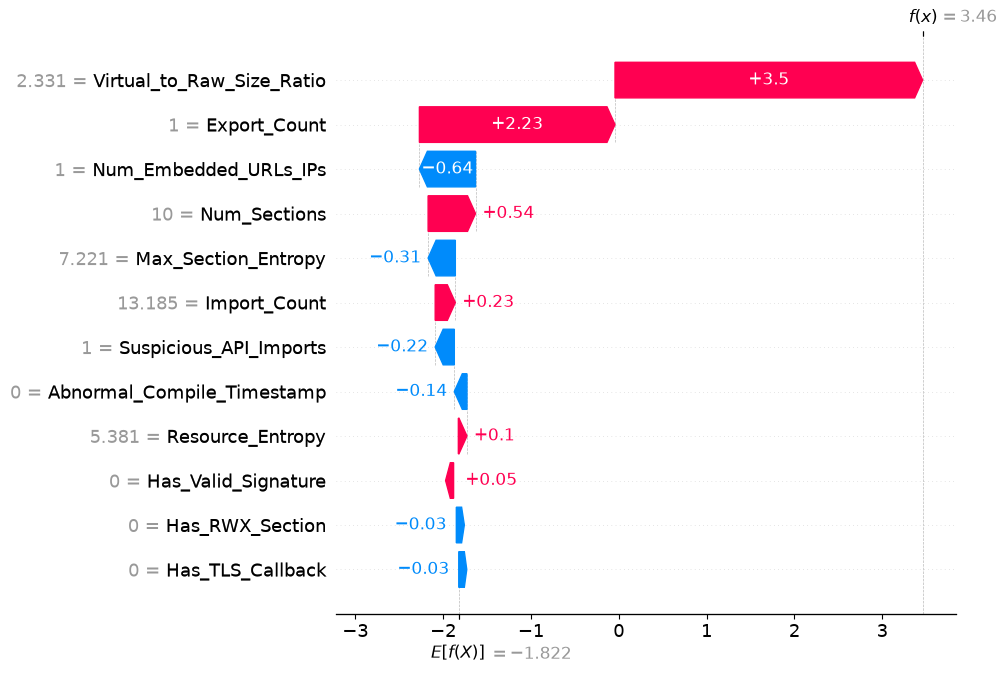

Base value: -1.8219166203198085
Num_Embedded_URLs_IPs        -0.639
Max_Section_Entropy          -0.310
Suspicious_API_Imports       -0.218
Abnormal_Compile_Timestamp   -0.144
Has_RWX_Section              -0.031
Has_TLS_Callback             -0.028
Has_Valid_Signature           0.054
Resource_Entropy              0.098
Import_Count                  0.229
Num_Sections                  0.540
Export_Count                  2.227
Virtual_to_Raw_Size_Ratio     3.503
dtype: float64


In [11]:
import shap
pre = fitted[bname].named_steps["imp"]; clf = fitted[bname].named_steps["clf"]
Xt = pd.DataFrame(pre.transform(X_test), columns=X.columns, index=X_test.index)
sv = shap.TreeExplainer(clf)(Xt)
if sv.values.ndim == 3: sv = sv[:,:,1]
shap.plots.beeswarm(sv, max_display=12)
pos = list(Xt.index).index(idx)
shap.plots.waterfall(sv[pos], max_display=12)
print("Base value:", sv.base_values[pos])
print(pd.Series(sv.values[pos], index=X.columns).sort_values().round(3))

In [12]:
COST_FP, COST_FN = 25, 500
def evaluate(y_true, p, t, cfp):
    tn, fp, fn, tp = confusion_matrix(y_true, (p>=t).astype(int), labels=[0,1]).ravel()
    return dict(t=t, TP=tp, TN=tn, FP=fp, FN=fn, precision=tp/(tp+fp), recall=tp/(tp+fn),
                cost=cfp*fp + COST_FN*fn, alerts=tp+fp)
ths = np.round(np.arange(0.01, 1.0, 0.01), 2)
out = []
for n in ["LogReg", bname]:
    oof = cross_val_predict(clone(models[n]), X_dev, y_dev, cv=cv, method="predict_proba")[:,1]  # DEV only
    p_test = fitted[n].predict_proba(X_test)[:,1]
    for cfp in [25, 2000]:
        dev_costs = [evaluate(y_dev, oof, t, cfp)["cost"] for t in ths]
        t_star = ths[int(np.argmin(dev_costs))]                       # selected on OOF, then frozen
        r = evaluate(y_test, p_test, t_star, cfp)                     # lockbox, evaluated once
        r.update(model=n, C_FP=cfp, theory=round(cfp/(cfp+COST_FN),3), OOF_cost=min(dev_costs),
                 cost_at_0_5=evaluate(y_test, p_test, 0.5, cfp)["cost"])
        out.append(r)
thr = pd.DataFrame(out)[["model","C_FP","theory","t","OOF_cost","TP","TN","FP","FN","precision","recall","cost","cost_at_0_5","alerts"]]
display(thr.round(3))

,model,C_FP,theory,t,OOF_cost,TP,TN,FP,FN,precision,recall,cost,cost_at_0_5,alerts
0,LogReg,25,0.048,0.28,72225,288,868,10,34,0.966,0.894,17250,18200,298
1,LogReg,2000,0.800,0.50,152500,286,870,8,36,0.973,0.888,34000,34000,294
2,"HistGradientBoosting (fallback, not LightGBM)",25,0.048,0.11,72850,290,841,37,32,0.887,0.901,16925,19225,327
3,"HistGradientBoosting (fallback, not LightGBM)",2000,0.800,0.72,155000,282,870,8,40,0.972,0.876,36000,37000,290
